# Task 5 — Masked Temporal Prediction

ทำนาย quantile ของข้อมูลที่ถูกซ่อนในแต่ละช่วงเวลา แล้วใช้ความผิดคาดพร้อมกันหลายกลุ่มพฤติกรรมเป็น anomaly score. ไม่ใช้คำตอบหรือสามองค์ประกอบของ baseline ในการฝึก. ไม่มี anomaly labels จึงยังวัด F3 ไม่ได้.

## 1. Setup และขอบเขต

Run All โหลดผลที่บันทึกไว้. การฝึกบน Test cohort ทำตาม workflow เดิมที่ผู้ใช้ร้องขอ แต่ยังไม่มีการยืนยันข้อยกเว้นกติกาจาก TA. Cross-fitting ลดการประเมินแถวที่ใช้ฝึก แต่ไม่ได้ทำให้การใช้ Test กลายเป็น Train ตามกติกา.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'Task5/models/masked_temporal_followup.py').exists())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from Task5.models import masked_temporal_followup as mt
OUT = mt.OUT
RUN_TRAINING = False

Matplotlib is building the font cache; this may take a moment.


## 2. Recipe ที่กำหนดก่อนดูผลเทียบ

30 channels × 4 periods; 24 masks (4 whole-period, 20 domain-period). MLP 192→96 ทำนาย q10/q50/q90, masked pinball loss, ไม่ป้อน target ที่ซ่อนเข้าโมเดล. แปลง asinh และพิกัด spherical XYZ; อายุบัญชีเป็น context; ไม่ใช้ ID, behavior_stability และ security flags. 3 folds × 3 seeds, train/inner-validation แยกภายในแต่ละ fold. คะแนนหลักเป็น domain surprise อันดับสองในแต่ละช่วงเวลา แล้วเลือกค่าสูงสุดข้ามเวลา. 2,046 alerts เป็นงบเทียบกับ baseline ไม่ใช่ prevalence ที่ทราบ.

In [2]:
display(pd.DataFrame([{'domain':k,'features':', '.join(v)} for k,v in mt.DOMAINS.items()]))
display(mt.CONFIG)
display(mt.structural_test())

,domain,features
0,access,"location_changes, device_count, ip_hash_entrop..."
1,engagement,"login_count, session_duration_mean, session_du..."
2,performance,"skill_rating, skill_trajectory, kda_mean, kda_..."
3,economy,"purchase_frequency, purchase_amount_mean, purc..."
4,social,"friend_adds, friend_removes, communication_fre..."


{'seeds': [173, 271, 389],
 'folds': 3,
 'split_seed': 619,
 'epochs': 60,
 'patience': 10,
 'batch': 512,
 'lr': 0.001,
 'threads': 4,
 'budget': 2046,
 'hidden': [192, 96],
 'quantiles': [0.1, 0.5, 0.9],
 'width_floor': 0.1,
 'primary': 'synchronized',
 'rule_exception': 'not independently confirmed; user requested prior workflow'}

{'masked_target_input_invariance': True,
 'loss_only_hidden_observed': True,
 'quantile_order': True,
 'channels': 30,
 'masks': 24}

## 3. Train หรือโหลด checkpoints

Checkpoint ทุก epoch เก็บ optimizer, RNG และ best weights. Saved fold scores ใช้ต่อเมื่อ source/config/data hash ตรง. ไม่ใช้ reference CSV จนกว่าจะสร้างคะแนนครบแล้ว.

In [3]:
if RUN_TRAINING:
    mt.run()
assert (OUT / 'report.json').exists(), 'ยังไม่มีผลครบ — ฝึกผ่าน script หรือเปิด RUN_TRAINING'
settings = json.loads((OUT / 'settings.json').read_text())
assert settings['raw_sha256'] == mt.sha(mt.RAW)
assert settings['code_sha256'] == mt.sha(mt.__file__)
report = json.loads((OUT / 'report.json').read_text())
scores = pd.read_parquet(OUT / 'predictions.parquet')
long = pd.read_parquet(OUT / 'crossfit_scores.parquet')

## 4. การทำนายข้อมูลที่ถูกซ่อน

Coverage ของช่วง q10–q90 มี nominal 80%. นี่วัดการทำนาย feature เท่านั้น ไม่ใช่ความแม่นยำตรวจโกง. Inner validation ถูกใช้เลือก epoch และ calibrate score จึงไม่ใช่ validation อิสระของคุณภาพ anomaly.

In [4]:
diagnostics = [json.loads(p.read_text()) for p in sorted(OUT.glob('seed*_fold*.json'))]
display(pd.DataFrame([{'seed':d['seed'],'fold':d['fold'],'epochs':d['epochs'],'best_pinball':d['best_pinball'],'heldout_interval_coverage':d['heldout']['interval_coverage']} for d in diagnostics]))

,seed,fold,epochs,best_pinball,heldout_interval_coverage
0,173,1,60,0.095918,0.828415
1,173,2,60,0.096249,0.832257
2,173,3,60,0.096614,0.826491
3,271,1,60,0.095857,0.825610
4,271,2,60,0.095566,0.835282
5,271,3,60,0.096397,0.822616
6,389,1,60,0.095295,0.827524
7,389,2,60,0.095770,0.826908
8,389,3,57,0.096712,0.825974


## 5. ความเสถียรข้าม seeds

,seed_a,seed_b,jaccard,spearman
0,173,271,0.471942,0.660974
1,173,389,0.465616,0.655242
2,271,389,0.466141,0.653667


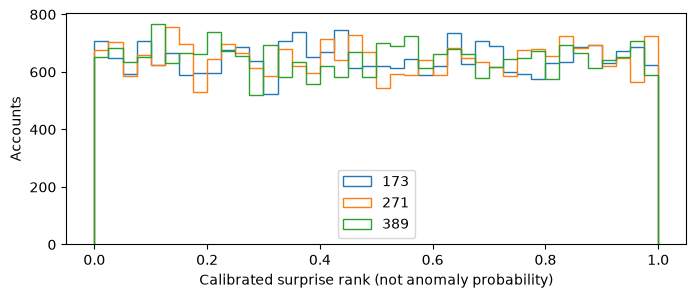

In [5]:
display(pd.DataFrame(report['stability']))
fig, ax = plt.subplots(figsize=(8,3))
for seed, g in long.groupby('seed'):
    ax.hist(g.synchronized,bins=40,histtype='step',label=str(seed))
ax.set(xlabel='Calibrated surprise rank (not anomaly probability)',ylabel='Accounts')
ax.legend(); plt.show()

## 6. เทียบคำตอบกับ 0.81771 และรุ่นก่อน

Agreement รวมมี normal จำนวนมาก จึงต้องอ่าน common alerts / Jaccard / added / removed ควบคู่. Public score ที่ระบุเป็นคะแนนรวม 5 Tasks. เปรียบเทียบนี้ไม่ใช้ย้อนเลือกสูตรหรือปรับ threshold.

,reference,public_overall_score,new_alerts,reference_alerts,common_alerts,added,removed,all_row_agreement,new_alert_overlap,alert_jaccard
0,density_auto_v1,0.81771,2046,2046,1048,998,998,0.922902,0.512219,0.344284
1,rank_fusion95_5_v1,0.80678,2046,2046,1046,1000,1000,0.922747,0.511241,0.343401
2,multiscale_representation_v1,0.73801,2046,2046,1096,950,950,0.926610,0.535679,0.365821
3,behavior_blocks5_v1,0.79798,2046,2046,1055,991,991,0.923442,0.515640,0.347382
4,tail_engineered_v20,0.75893,2046,6531,1434,612,5097,0.779482,0.700880,0.200756


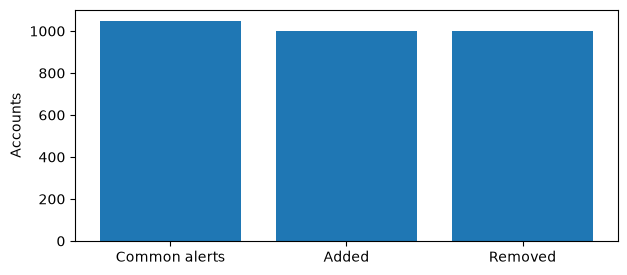

In [6]:
comparison = pd.read_parquet(OUT / 'reference_comparison.parquet')
cols=['reference','public_overall_score','new_alerts','reference_alerts','common_alerts','added','removed','all_row_agreement','new_alert_overlap','alert_jaccard']
display(comparison[cols])
row = comparison.iloc[0]
fig, ax = plt.subplots(figsize=(7,3))
ax.bar(['Common alerts','Added','Removed'],[row.common_alerts,row.added,row.removed])
ax.set_ylabel('Accounts');plt.show()

## 7. ตรวจบัญชีที่คำตอบเปลี่ยน

แสดงหลักฐาน surprise แยก domain; ไม่เรียกเพิ่ม/ลดว่า true/false positive เพราะยังไม่มี labels.

In [7]:
diff = pd.read_parquet(OUT / 'baseline_row_comparison.parquet')
display(diff.groupby('change').size().rename('accounts').to_frame())
domain_cols=[c for c in long if any(c.startswith(d+'_') for d in mt.DOMAINS)]
context=long.groupby('row_index')[domain_cols].median()
for change in ['added','removed']:
    display(diff[diff.change.eq(change)].sort_values('synchronized',ascending=False).head(10).join(context))

,accounts
change,
added,998
normal_both,22845
removed,998
retained,1048


,id,player_id,synchronized,single,prediction,single_prediction,baseline_prediction,change,access_1,access_2,...,performance_3,performance_4,economy_1,economy_2,economy_3,economy_4,social_1,social_2,social_3,social_4
11080,ANS11081,P021335,0.976062,0.968726,1,1,0,added,0.693967,0.832446,...,0.449902,0.330812,0.566213,0.522798,0.436320,1.689988,0.485607,0.585073,0.602955,0.661277
6981,ANS06982,P008884,0.974517,0.968726,1,1,0,added,0.905833,0.932521,...,0.548461,0.779502,0.651901,0.833655,1.070477,0.626779,0.345528,0.557302,0.516504,0.480942
4288,ANS04289,P020248,0.974517,0.974131,1,1,0,added,0.755058,0.764440,...,0.433473,0.461148,0.444878,0.716942,0.689924,0.523032,0.629246,0.507488,0.669345,0.843552
11515,ANS11516,P025636,0.972973,0.969884,1,1,0,added,0.659110,0.993929,...,0.884510,0.711703,0.723572,1.252162,0.677219,1.854344,0.934424,0.837959,0.518857,0.719996
3395,ANS03396,P014090,0.972973,0.967568,1,1,0,added,1.302862,0.658199,...,0.828990,0.536796,0.620663,0.457903,0.645256,2.106286,0.462927,0.788993,0.360390,0.534956
6816,ANS06817,P021920,0.972587,0.969498,1,1,0,added,0.836199,0.682114,...,0.572179,0.370517,0.724469,0.539377,0.733313,1.639473,0.720296,0.600242,0.462814,0.690951
21371,ANS21372,P011115,0.971429,0.970270,1,1,0,added,0.495411,0.607101,...,0.557855,0.368021,0.807834,0.315689,1.071525,1.594664,0.602143,0.527019,0.849718,0.736440
17937,ANS17938,P012410,0.970656,0.970656,1,1,0,added,0.857196,0.811611,...,0.387648,0.454623,0.895844,0.476983,0.218683,1.264738,0.487739,0.785633,0.926494,0.938916
13385,ANS13386,P011652,0.968726,0.932046,1,1,0,added,0.713148,1.139395,...,0.699162,1.249083,0.684772,0.531210,0.545459,0.601152,0.895252,0.896304,0.823226,0.936132
3313,ANS03314,P002306,0.968726,0.964479,1,1,0,added,0.893976,1.207143,...,0.964861,1.327057,0.478129,0.518157,0.843252,0.715404,0.781737,0.808204,0.968872,0.903865


,id,player_id,synchronized,single,prediction,single_prediction,baseline_prediction,change,access_1,access_2,...,performance_3,performance_4,economy_1,economy_2,economy_3,economy_4,social_1,social_2,social_3,social_4
17570,ANS17571,P003736,0.902703,0.849807,0,0,1,removed,0.638669,0.621249,...,0.721181,0.800693,0.729101,0.689686,0.615379,1.187376,0.498731,0.608505,0.498110,0.801276
22699,ANS22700,P023635,0.902703,0.966409,0,1,1,removed,0.486806,0.409700,...,0.636905,0.654352,0.839369,0.801910,0.570580,2.092273,0.278538,0.677917,0.693356,0.602894
4273,ANS04274,P016256,0.902317,0.775676,0,0,1,removed,0.541639,0.707922,...,0.459632,0.490312,0.749551,0.631121,0.814280,0.529908,1.109876,0.457117,0.959074,0.550402
17664,ANS17665,P024429,0.902317,0.676062,0,0,1,removed,0.608936,0.551767,...,0.617539,0.564238,0.632369,0.670235,0.712797,0.460014,0.512619,0.499725,0.973500,0.795047
13069,ANS13070,P009246,0.901931,0.755598,0,0,1,removed,0.380861,0.928919,...,0.625425,0.617565,0.772162,0.781158,0.298877,0.933193,0.339181,0.475052,0.484289,0.831881
11741,ANS11742,P009255,0.901158,0.813900,0,0,1,removed,0.731354,0.679392,...,0.809023,0.661029,0.608306,0.691520,0.841041,0.841296,0.557757,1.137531,0.969645,0.594601
1862,ANS01863,P012650,0.901158,0.568340,0,0,1,removed,0.702922,0.502174,...,0.665099,0.641023,0.657385,0.487716,0.559625,0.950394,0.528927,0.799609,0.597636,0.592689
5992,ANS05993,P013879,0.900772,0.952896,0,1,1,removed,0.593004,0.468343,...,0.572519,0.458707,0.962620,0.615510,0.663407,0.367921,0.583394,0.343501,0.570549,0.273815
24948,ANS24949,P006789,0.900386,0.936293,0,1,1,removed,0.517518,0.411135,...,0.379500,0.578751,0.567361,0.876005,0.688904,1.039484,0.696879,0.680405,0.976809,0.360780
1902,ANS01903,P024596,0.900000,0.816602,0,0,1,removed,0.411320,0.684127,...,0.947062,0.631527,0.703381,0.644002,0.961685,0.795338,0.511397,0.490173,0.565511,0.603313


## 8. Artifacts และข้อจำกัด

ผลหลักอยู่ predictions.parquet, รายบัญชี baseline_row_comparison.parquet, โมเดล 9 checkpoints. ไม่สร้าง combined submission และไม่ส่ง Kaggle. วิธีนี้อาจพลาดความผิดปกติที่เกิดทั้งสี่ช่วงเวลาอย่างสม่ำเสมอ เพราะข้อมูลช่วงอื่นช่วยทำนายได้; การเน้นสอง domains อาจพลาด anomaly เฉพาะ domain. ไม่มีหลักฐานว่าจะชนะ 0.81771.

In [8]:
assert len(scores)==25889 and scores.id.is_unique
assert int(scores.prediction.sum())==2046
assert len(long)==3*len(scores)
assert not long.duplicated(['row_index','seed']).any()
display({'output':str(OUT),'models':len(list(OUT.glob('seed*_fold*.pt'))),'submitted_to_kaggle':False})

{'output': '/Users/meng/dev/MyUniversity/CPE342-MachineLearning/CPE342-Kaggle/Task5/models/results/masked_temporal_v1',
 'models': 9,
 'submitted_to_kaggle': False}